<a href="https://colab.research.google.com/github/shanzamumtaz954-alt/An-FPS-style-target-shooting-game-built-with-React/blob/main/World_Bank_Visual_Analytics_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup & Imports

**Purpose:** Import the required libraries and apply a consistent visual theme.

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 1: Load Data

**Purpose:** Load the World Bank indicator data and country metadata.

In [31]:

path_ind = "/content/drive/MyDrive/Indicators.csv"
path_country = "/content/drive/MyDrive/Country.csv"

df_ind = pd.read_csv(path_ind)
df_country = pd.read_csv(path_country)

print("Indicator data shape:", df_ind.shape)
print("Country metadata shape:", df_country.shape)
display(df_ind.head())
display(df_country.head())

Indicator data shape: (5656458, 6)
Country metadata shape: (247, 31)


,CountryName,CountryCode,IndicatorName,IndicatorCode,Year,Value
0,Arab World,ARB,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,1960,1.335609e+02
1,Arab World,ARB,Age dependency ratio (% of working-age populat...,SP.POP.DPND,1960,8.779760e+01
2,Arab World,ARB,"Age dependency ratio, old (% of working-age po...",SP.POP.DPND.OL,1960,6.634579e+00
3,Arab World,ARB,"Age dependency ratio, young (% of working-age ...",SP.POP.DPND.YG,1960,8.102333e+01
4,Arab World,ARB,Arms exports (SIPRI trend indicator values),MS.MIL.XPRT.KD,1960,3.000000e+06


,CountryCode,ShortName,TableName,LongName,Alpha2Code,CurrencyUnit,SpecialNotes,Region,IncomeGroup,Wb2Code,...,GovernmentAccountingConcept,ImfDataDisseminationStandard,LatestPopulationCensus,LatestHouseholdSurvey,SourceOfMostRecentIncomeAndExpenditureData,VitalRegistrationComplete,LatestAgriculturalCensus,LatestIndustrialData,LatestTradeData,LatestWaterWithdrawalData
0,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2013.0,2000.0
1,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,Budgetary central government,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2011.0,2013.0,2006.0
2,DZA,Algeria,Algeria,People's Democratic Republic of Algeria,DZ,Algerian dinar,NaN,Middle East & North Africa,Upper middle income,DZ,...,Budgetary central government,General Data Dissemination System (GDDS),2008,"Multiple Indicator Cluster Survey (MICS), 2012","Integrated household survey (IHS), 1995",NaN,NaN,2010.0,2013.0,2001.0
3,ASM,American Samoa,American Samoa,American Samoa,AS,U.S. dollar,NaN,East Asia & Pacific,Upper middle income,AS,...,NaN,NaN,2010,NaN,NaN,Yes,2007,NaN,NaN,NaN
4,ADO,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,NaN,2011. Population data compiled from administra...,NaN,NaN,Yes,NaN,NaN,2006.0,NaN


## Step 2: Filter and Pivot

**Purpose:** Select the three indicators and reshape the data into one row per country and year.

In [32]:
indicators_needed = [
    "Life expectancy at birth, total (years)",
    "GDP per capita (current US$)",
    "CO2 emissions (metric tons per capita)"
]

df_filtered = df_ind[
    df_ind["IndicatorName"].isin(indicators_needed)
].dropna(subset=["Value"]).copy()

df_pivot = df_filtered.pivot_table(
    index=["CountryName", "CountryCode", "Year"],
    columns="IndicatorName",
    values="Value",
    aggfunc="mean"
).reset_index()

df_pivot.rename(columns={
    "Life expectancy at birth, total (years)": "Life_Expectancy",
    "GDP per capita (current US$)": "GDP_per_Capita",
    "CO2 emissions (metric tons per capita)": "CO2_Emissions"
}, inplace=True)

display(df_pivot.head())
print("Pivoted data shape:", df_pivot.shape)

IndicatorName,CountryName,CountryCode,Year,CO2_Emissions,GDP_per_Capita,Life_Expectancy
0,Afghanistan,AFG,1960,0.046068,59.787681,32.328512
1,Afghanistan,AFG,1961,0.053615,59.890037,32.777439
2,Afghanistan,AFG,1962,0.073781,58.505995,33.219902
3,Afghanistan,AFG,1963,0.074251,78.802587,33.657878
4,Afghanistan,AFG,1964,0.086317,82.231395,34.092878


Pivoted data shape: (13036, 6)


## Step 3: Merge and Clean Data

**Purpose:** Add country metadata, remove aggregate entries, and identify the latest available year.

In [33]:
country_metadata = df_country[["CountryCode", "Region", "IncomeGroup"]].drop_duplicates(
    subset=["CountryCode"]
)

df_final = pd.merge(
    df_pivot,
    country_metadata,
    on="CountryCode",
    how="left"
)

df_final = df_final[
    df_final["Region"].notna()
    & (df_final["Region"].astype(str).str.strip() != "")
    & (df_final["Region"].astype(str).str.strip().str.lower() != "aggregates")
].dropna(subset=["IncomeGroup"]).copy()


latest_year = 2010
df_latest = df_final[df_final["Year"] == latest_year].copy()

print("Latest year in the cleaned dataset:", latest_year)
print("Cleaned data shape:", df_final.shape)
print("Latest year data shape:", df_latest.shape)
display(df_final.head())

Latest year in the cleaned dataset: 2010
Cleaned data shape: (11221, 8)
Latest year data shape: (209, 8)


,CountryName,CountryCode,Year,CO2_Emissions,GDP_per_Capita,Life_Expectancy,Region,IncomeGroup
0,Afghanistan,AFG,1960,0.046068,59.787681,32.328512,South Asia,Low income
1,Afghanistan,AFG,1961,0.053615,59.890037,32.777439,South Asia,Low income
2,Afghanistan,AFG,1962,0.073781,58.505995,33.219902,South Asia,Low income
3,Afghanistan,AFG,1963,0.074251,78.802587,33.657878,South Asia,Low income
4,Afghanistan,AFG,1964,0.086317,82.231395,34.092878,South Asia,Low income


In [34]:
print("Minimum Year in dataset:", df_final['Year'].min())
print("Maximum Year in dataset:", df_final['Year'].max())

Minimum Year in dataset: 1960
Maximum Year in dataset: 2014


## Step 4: Visual Analytics

**Purpose:** Explore indicator relationships and distributions before creating the final charts.

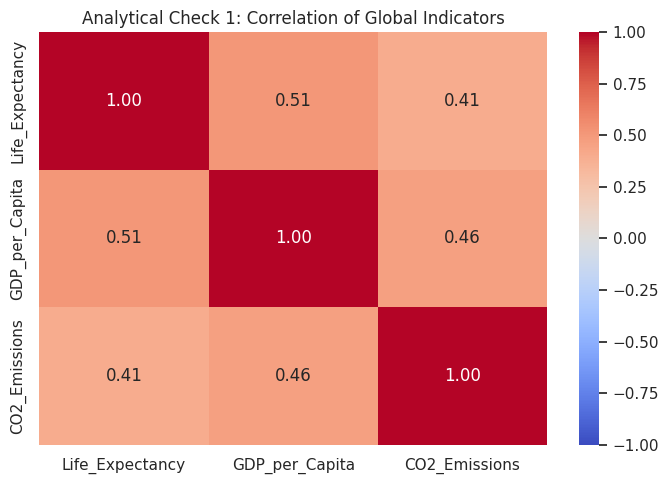

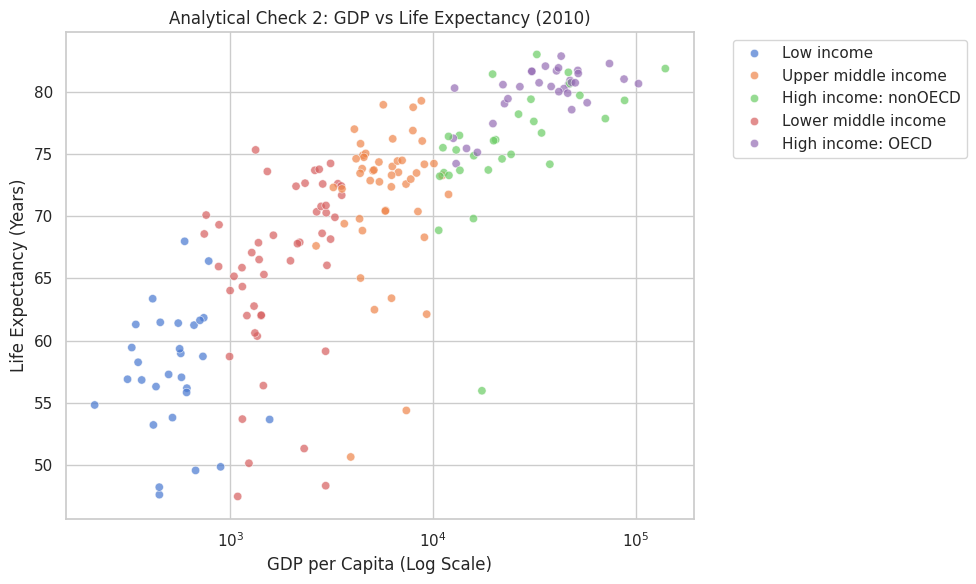

In [35]:
corr_matrix = df_final[
    ["Life_Expectancy", "GDP_per_Capita", "CO2_Emissions"]
].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Analytical Check 1: Correlation of Global Indicators")
plt.tight_layout()
plt.show()

scatter_data = df_latest.dropna(
    subset=["GDP_per_Capita", "Life_Expectancy", "IncomeGroup"]
)
scatter_data = scatter_data[scatter_data["GDP_per_Capita"] > 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=scatter_data,
    x="GDP_per_Capita",
    y="Life_Expectancy",
    hue="IncomeGroup",
    alpha=0.7
)
plt.xscale("log")
plt.title(f"Analytical Check 2: GDP vs Life Expectancy ({latest_year})")
plt.xlabel("GDP per Capita (Log Scale)")
plt.ylabel("Life Expectancy (Years)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 5: Exploration of Visualisations

**Purpose:** Test alternative chart designs and document the rejected and considered iterations.

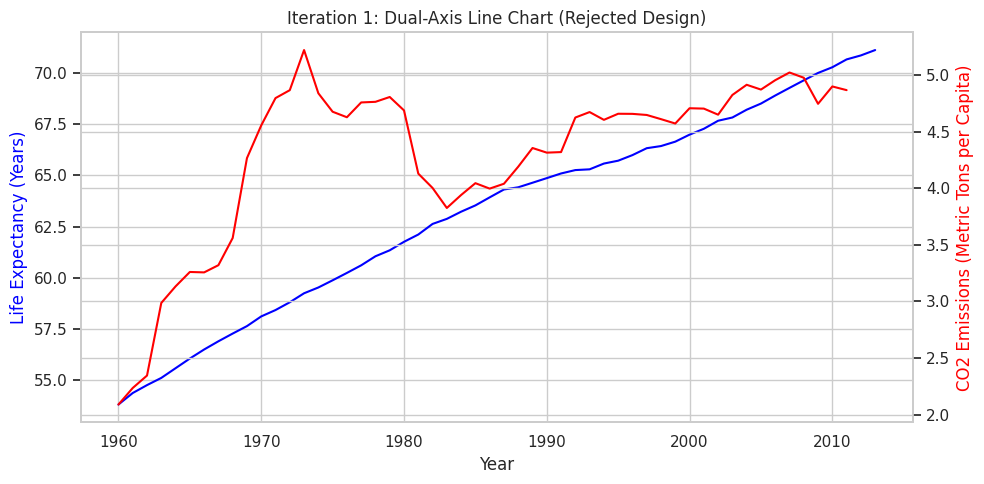

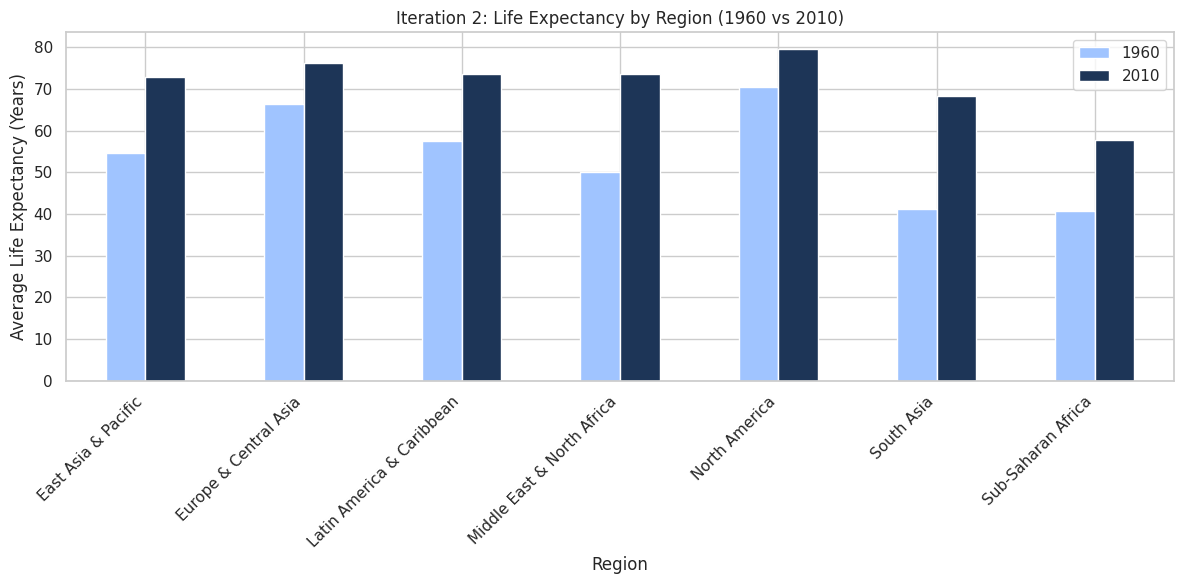

In [36]:
global_trend = (
    df_final.groupby("Year")[["Life_Expectancy", "CO2_Emissions"]]
    .mean()
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.plot(
    global_trend["Year"],
    global_trend["Life_Expectancy"],
    color="blue"
)
ax2.plot(
    global_trend["Year"],
    global_trend["CO2_Emissions"],
    color="red"
)

ax1.set_ylabel("Life Expectancy (Years)", color="blue")
ax2.set_ylabel("CO2 Emissions (Metric Tons per Capita)", color="red")
ax1.set_xlabel("Year")
plt.title("Iteration 1: Dual-Axis Line Chart (Rejected Design)")
fig.tight_layout()
plt.show()

# Iteration 2: Grouped bar chart
df_1960 = (
    df_final[df_final["Year"] == 1960]
    .groupby("Region")["Life_Expectancy"]
    .mean()
)
df_2010_reg = (
    df_final[df_final["Year"] == latest_year]
    .groupby("Region")["Life_Expectancy"]
    .mean()
)

region_comp = pd.DataFrame({
    "1960": df_1960,
    str(latest_year): df_2010_reg
}).dropna()

region_comp.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#A0C4FF", "#1D3557"]
)
plt.title(f"Iteration 2: Life Expectancy by Region (1960 vs {latest_year})")
plt.xlabel("Region")
plt.ylabel("Average Life Expectancy (Years)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Step 6: Ethical Assessment

**Purpose:** Examine missing CO2 data across income groups.

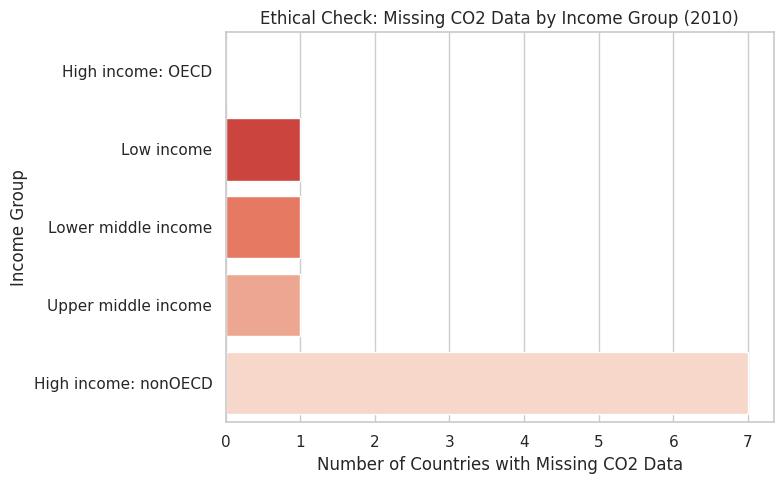

,Missing CO2 Records
IncomeGroup,
High income: OECD,0
Low income,1
Lower middle income,1
Upper middle income,1
High income: nonOECD,7


In [39]:
missing_co2 = (
    df_latest.groupby("IncomeGroup")["CO2_Emissions"]
    .apply(lambda values: values.isna().sum())
    .sort_values()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=missing_co2.values,
    y=missing_co2.index,
    palette="Reds_r"
)
plt.title(f"Ethical Check: Missing CO2 Data by Income Group ({latest_year})")
plt.xlabel("Number of Countries with Missing CO2 Data")
plt.ylabel("Income Group")
plt.tight_layout()
plt.show()

display(missing_co2.rename("Missing CO2 Records").to_frame())

## Step 7: Management Memo Visualisations

**Purpose:** Create the final storytelling charts for the management memo.

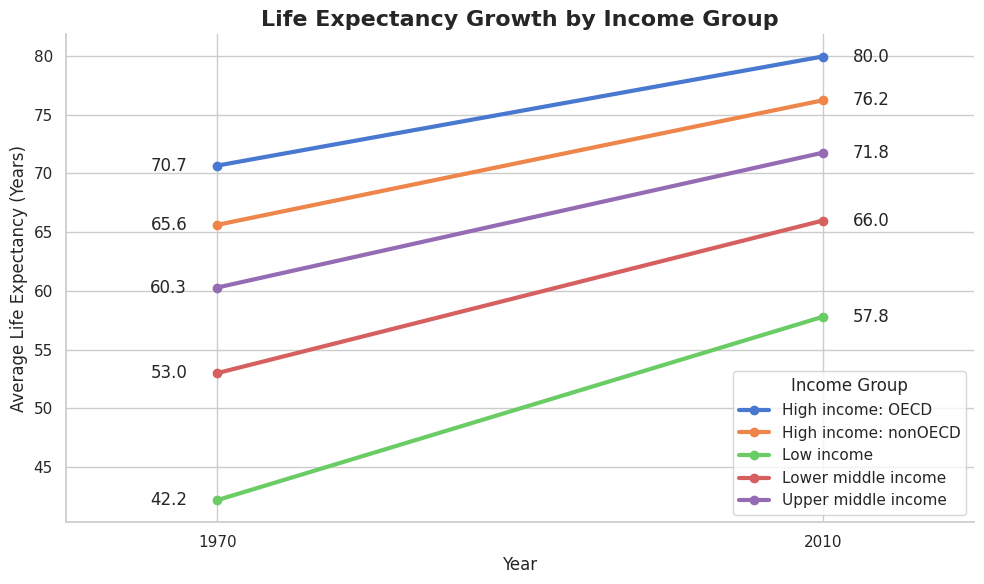

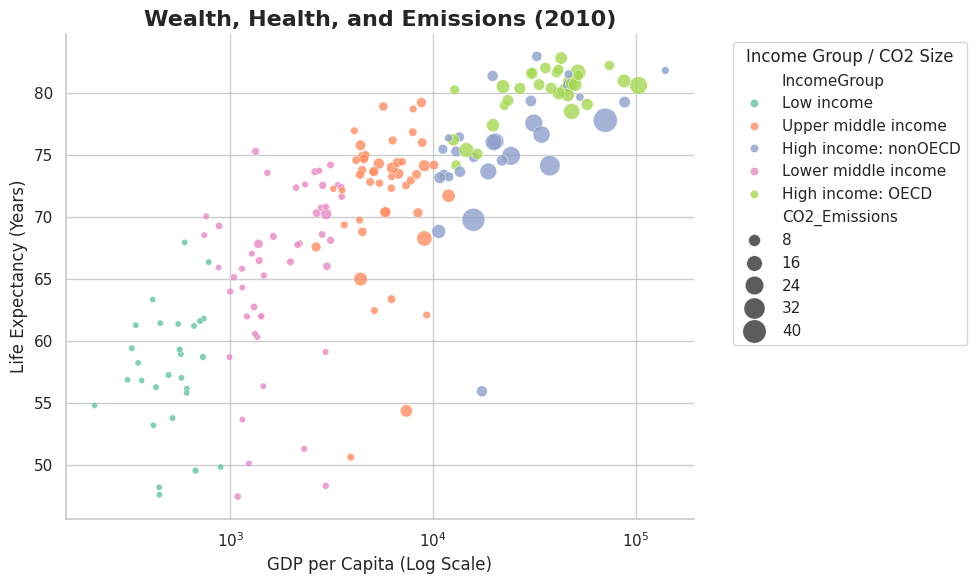

In [40]:
df_slope = (
    df_final[df_final["Year"].isin([1970, latest_year])]
    .groupby(["IncomeGroup", "Year"])["Life_Expectancy"]
    .mean()
    .unstack()
)

# Keep only income groups with values for both comparison years.
df_slope = df_slope.dropna(subset=[1970, latest_year])

plt.figure(figsize=(10, 6))

for income_group, row in df_slope.iterrows():
    plt.plot(
        [1970, latest_year],
        [row[1970], row[latest_year]],
        marker="o",
        linewidth=3,
        label=income_group
    )
    plt.text(1968, row[1970], f"{row[1970]:.1f}", ha="right", va="center")
    plt.text(
        latest_year + 2,
        row[latest_year],
        f"{row[latest_year]:.1f}",
        ha="left",
        va="center"
    )

plt.xticks([1970, latest_year])
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy (Years)")
plt.title("Life Expectancy Growth by Income Group", fontsize=16, weight="bold")
plt.legend(title="Income Group", loc="lower right")
plt.xlim(1960, latest_year + 10)
sns.despine()
plt.tight_layout()
plt.show()

# Wealth, health, and emissions (bubble scatter)
bubble_data = df_latest.dropna(
    subset=["GDP_per_Capita", "Life_Expectancy", "CO2_Emissions", "IncomeGroup"]
)
bubble_data = bubble_data[bubble_data["GDP_per_Capita"] > 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=bubble_data,
    x="GDP_per_Capita",
    y="Life_Expectancy",
    hue="IncomeGroup",
    size="CO2_Emissions",
    sizes=(20, 300),
    alpha=0.8,
    palette="Set2"
)
plt.xscale("log")
plt.title(f"Wealth, Health, and Emissions ({latest_year})", fontsize=16, weight="bold")
plt.xlabel("GDP per Capita (Log Scale)")
plt.ylabel("Life Expectancy (Years)")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    title="Income Group / CO2 Size"
)
sns.despine()
plt.tight_layout()
plt.show()

## Final Data Check

**Purpose:** Review the final dataset dimensions and missing-value counts.

In [41]:
print("Final dataset shape:", df_final.shape)
print("Latest year analysed:", latest_year)
print("\nMissing values in the latest-year dataset:")
display(df_latest[[
    "Life_Expectancy",
    "GDP_per_Capita",
    "CO2_Emissions"
]].isna().sum().to_frame("Missing Values"))

Final dataset shape: (11221, 8)
Latest year analysed: 2010

Missing values in the latest-year dataset:


,Missing Values
Life_Expectancy,9
GDP_per_Capita,14
CO2_Emissions,10
